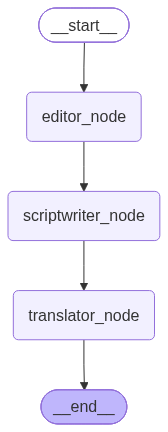

In [11]:
import os 
from typing import TypedDict

# first of all we have to create State
class pipelineState(TypedDict):

    raw_input : str
    edited_text : str 
    script_text : str
    final_text : str

from langchain_groq import ChatGroq
from dotenv import load_dotenv
load_dotenv()

llm = ChatGroq( model="qwen/qwen3.8-27b", temperature=0.7)

def editor_node(state: pipelineState)-> dict:

    prompt = f'''You're an expert copyeditor. Clean up the following raw text,
    fix any grammatical errors, spelling mistakes, and smooth out the transition flow, while keeping the core message intact. Return only the edited tex. \n\n
    text:\n{state['raw_input']}
    '''
    response = llm.invoke(prompt)
    return{'edited_text' : response.content.strip()}

def scriptwriter_node(state: pipelineState)-> dict:

    prompt = f'''You are a charismatic YouTube content creator. Take this edited text and transformation
    "it into a highly engaging, punchy, conversational video script hook. Make it sound
    "like a real person speaking passionately. Return only the script content. \n\n"
    f"Edited Text: In{state['edited_text']}'''

    response = llm.invoke(prompt)
    return {'script_text' : response.content.strip()}

def translator_node(state: pipelineState) -> dict:

    prompt = (
        "You are an expert content localizer for the Pakistani market. Take the following script "
        "and convert it into natural, flowing 'Roman Urdu'. Do not simply translate it sentence-by-sentence "
        "or repeat information. Alternating comfortably between RomanUrdu and English phrases just like "
        "an intellectual tech educator would speak naturally on a live stream. Keep the energy high! "
        "Return only the final RomanUrdu text.\n\n"
        f"Script:\n{state['script_text']}"
    )

    response = llm.invoke(prompt)
    return {'final_text': response.content.strip()}

# now your state and nodes are ready and now it is time to create graph 

from langgraph.graph import StateGraph, START, END

# add graph
graph = StateGraph(pipelineState)

# add the nodes in this graph
graph.add_node('editor_node', editor_node)
graph.add_node('scriptwriter_node', scriptwriter_node)
graph.add_node('translator_node', translator_node)

# add edges (sequential - one after another)
graph.add_edge(START, 'editor_node')
graph.add_edge('editor_node','scriptwriter_node')
graph.add_edge('scriptwriter_node', 'translator_node')

# compile the graph
workflow = graph.compile()
workflow

In [12]:
result = workflow.invoke({
    'raw_input': ('''AI is no longer something from the future. It is already part of our daily lives.

We use AI when we search something on Google, watch recommendations on YouTube, use Google Maps, talk to virtual assistants, or even when our phones recognize our faces.

But AI is much bigger than that.

Today, AI can write code, create images, generate videos, analyze huge amounts of data, and even help doctors detect diseases. It can do in seconds what might take a human hours or even days.

But there is another side to AI.

AI can replace some jobs, spread misinformation, create fake images and videos, and make people overly dependent on technology. If we use it without understanding its risks, it can cause serious problems.

So, I don't think the real question is, "Will AI replace humans?"

The better question is, "How will humans use AI?"

AI itself is just a tool. A hammer can build a house or break a window. The result depends on the person using it.

The future will probably not belong to people who compete against AI.

It will belong to people who know how to work with it.
''')
})

print( "You're results are \n\n",result['final_text'])

You're results are 

 Scrolling band karo. Seriously, ruk jao.

Aap abhi, is waqt, AI ka istemal kar rahe ho. Haan, jo aapne abhi kiya, wo AI tha.

Woh search bar? AI. Woh YouTube recommendations jo aapko screen pe chipkaye rakhte hain? AI. Google Maps ko pata chalna ke aap late ho? AI. Aapke phone ka face unlock? Woh bhi AI hai.

Yeh koi sci-fi movie ka plot nahi hai jo aane wala hai. Yeh toh pehle se hi aapke din raat ki routine ki kumaar mein bikhra hua hai.

Lekin asli baat yeh hai jo aaj kal zyada tar log miss kar rahe hain.

Hum sochte hain ke AI sirf filters aur chatbots ke liye hai. Yeh ek bada galti hai.

Aaj kal AI complex code likh raha hai, hyper-realistic videos generate kar raha hai, aur itne bade data sets analyze kar raha hai ke insani team ko usme saalon lag jate. Jo kaam dino mein hota tha, woh ab ek pal mein ho jata hai.

Lekin—aur yeh wo bada "lekin" hai—ek dark side bhi hai.

Job displacement. Misinformation. Deepfakes itne real lagte hain ke aap takdeer nahi kar s